<a href="https://colab.research.google.com/github/ramithuh/differentiable-trees/blob/optimized-elves/viz-tools/wandb_plotly_retrieve.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import plotly.io as pio
import plotly.graph_objects as go
import json
import wandb
import networkx as nx
import matplotlib.pyplot as plt


In [ ]:
!pip install wandb -qqq
!pip install -U kaleido -qqq

In [ ]:
# Replace 'your-api-key' with your actual API key
wandb.login(key='d27e308c4d474bca02d33100ac03f779025ba5f5')

wandb: Currently logged in as: ramithx1 (fypteam-e77eba03). Use `wandb login --relogin` to force relogin
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc


True

In [ ]:
api = wandb.Api()
# Get the run ID
run_id = "ramithx1/Batch-Run-Maximum-Parsimony-A100-META-optimized/7iafn305"
run = api.run(run_id)

In [ ]:

# List all files in 'media/plotly'
plotly_files = [file for file in run.files() if file.name.startswith('media/plotly/Seq')]

# Sort the files based on the number after 'Seq_'
plotly_files.sort(key=lambda file: int(file.name.split('_')[1]))
#best_

# Print the names of the files
c = 0
for file in plotly_files:
    print(file.name)
    c+=1

media/plotly/Seq_2_e4b84e3aed7c504ec71b.plotly.json
media/plotly/Seq_3_f3cd806c9ab53d265a3c.plotly.json
media/plotly/Seq_4_4f04f2802239cacf5d95.plotly.json
media/plotly/Seq_5_f70afbd6a7d220fbe1b5.plotly.json
media/plotly/Seq_6_72bb673d9d26455daf81.plotly.json
media/plotly/Seq_7_3dd1c84fa040f11acbc7.plotly.json
media/plotly/Seq_8_3f89491a65bc20cbfd39.plotly.json
media/plotly/Seq_9_beffd4f75c1f8808ed6a.plotly.json
media/plotly/Seq_10_9ad11f7df1310bb95dd0.plotly.json
media/plotly/Seq_11_95dc5e49d964ac7e2b3b.plotly.json
media/plotly/Seq_12_c87236ec63e527f08e7c.plotly.json
media/plotly/Seq_13_e2bf1700d5341068ff60.plotly.json
media/plotly/Seq_14_4aaa08bdf7e294d9418d.plotly.json
media/plotly/Seq_15_cbb335fd119dbc068fc2.plotly.json
media/plotly/Seq_16_72f2e3bc494c4cf6a7d8.plotly.json
media/plotly/Seq_17_c0fda10e39aaee451da3.plotly.json
media/plotly/Seq_18_8b0252f5475b0d31e12e.plotly.json
media/plotly/Seq_19_a84f742d8509c0dce089.plotly.json
media/plotly/Seq_20_3acb3f785d5ec0c374c7.plotly.json
m

In [ ]:
c

30

In [ ]:
def draw_plot(file_name):

  # Get the file
  file = run.file(file_name)

  # Download the file
  file.download(replace=True)

  # Load the JSON into a Plotly Figure
  with open(file.name, 'r') as f:
      fig_dict = json.load(f)

  fig = go.Figure(fig_dict)

  fig.update_traces(showscale=False)
  fig.show()

  z_matrix = np.array(fig_dict['data'][0]['z'])

  return z_matrix


In [ ]:
import plotly.express as px

In [ ]:
def save_image(i):
  file_name = plotly_files[i].name

  # Get the file
  file = run.file(file_name)

  # Download the file
  file.download(replace=True)

  # Load the JSON into a Plotly Figure
  with open(plotly_files[i].name, 'r') as f:
      fig_dict = json.load(f)

  #transpose trace
  # for trace in fig_dict['data']:
  #     if 'z' in trace:
  #         trace['z'] = list(map(list, zip(*trace['z'])))

  def remove_coloraxis(d):
      if isinstance(d, dict):
          if 'coloraxis' in d:
              del d['coloraxis']
          for k, v in d.items():
              remove_coloraxis(v)
      elif isinstance(d, list):
          for i in d:
              remove_coloraxis(i)

  remove_coloraxis(fig_dict)

  seqs = np.array(fig_dict['data'][0]['z'])


  # Create a figure from the dictionary
  fig = px.imshow(seqs,   text_auto=True, color_continuous_scale='YlGnBu')

  fig.update_traces(textfont_size=1)  # Set the desired font size

  # fig = go.Figure(fig_dict)

  # fig.update_traces(showscale=False)
  fig.show()


  # Save the figure as a PDF
  pio.write_image(fig, f"figure_{i}.pdf",scale=5, width=1080, height=1080)



In [ ]:
save_image(0)

In [ ]:
save_image(29)

In [ ]:

# List all files in 'media/plotly'
tree_files = [file for file in run.files() if file.name.startswith('media/plotly/tree')]

#best_tree_adj
# Sort the files based on the number after 'Seq_'
tree_files.sort(key=lambda file: int(file.name.split('_')[1]))

# Print the names of the files
c = 0
for file in tree_files:
    print(file.name)
    c+=1

media/plotly/tree matrix_2_db69a71dfba87839c52c.plotly.json
media/plotly/tree matrix_3_bcaa22997c4578bffa65.plotly.json
media/plotly/tree matrix_4_1e37a381693607dbea38.plotly.json
media/plotly/tree matrix_5_3086c3ef50d1a1c2d1b9.plotly.json
media/plotly/tree matrix_6_90fee52148f083e4eeb1.plotly.json
media/plotly/tree matrix_7_6e5644b7e07f1bb8a31b.plotly.json
media/plotly/tree matrix_8_19f4788e2c3173ef23ad.plotly.json
media/plotly/tree matrix_9_ccde6cb9620eeb69d246.plotly.json
media/plotly/tree matrix_10_30494e364a5d7ddca92b.plotly.json
media/plotly/tree matrix_11_d572e11b885df2d14a55.plotly.json
media/plotly/tree matrix_12_dc896acb0fbe3bb01388.plotly.json
media/plotly/tree matrix_13_08fd2ec142e1fcfa0e57.plotly.json
media/plotly/tree matrix_14_3eb5125419ca57658992.plotly.json
media/plotly/tree matrix_15_657025e25a0eda766aa6.plotly.json
media/plotly/tree matrix_16_7a8b58f5e2910e16693a.plotly.json
media/plotly/tree matrix_17_a839c9029798b129e580.plotly.json
media/plotly/tree matrix_18_ac6e

In [ ]:
import jax.numpy as jnp
import jax.nn as nn

In [ ]:
def discretize_tree_topology(tree , n_nodes):
    '''
        Returns the one-hot encoding of the given soft tree topology

        Args:
            tree : soft tree topology (softmax applied over the rows)
            n_nodes : number of total nodes in the tree
        Returns:
            t_q : one-hot encoding of the tree topology 
    '''

    t_argmax = np.argmax(tree,axis = 1)
    t_q = nn.one_hot(t_argmax, n_nodes)
    
    return t_q

In [ ]:
z = draw_plot(tree_files[0].name)

In [ ]:
z.shape

(63, 63)

<ipython-input-222-5107b7811844>:23: DeprecationWarning:

nx.nx_pydot.graphviz_layout depends on the pydot package, which hasknown issues and is not actively maintained. Consider usingnx.nx_agraph.graphviz_layout instead.

See https://github.com/networkx/networkx/issues/5723



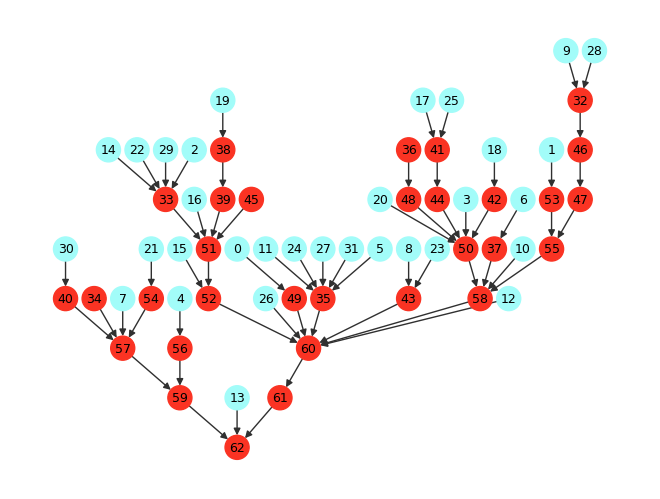

In [ ]:
adjacency_matrix = discretize_tree_topology(z,63)

adjacency_matrix = adjacency_matrix.at[-1,-1].set(0)

rows, cols = np.where(adjacency_matrix == 1)
edges = zip(rows.tolist(), cols.tolist())


gr = nx.DiGraph()#nx.DiGraph
gr.add_edges_from(edges)

color_map = []
for node in gr:
    if(node >= n_leaves):
        color_map.append('#fa3323')
    else:
        color_map.append('#a2fcf9')
    

# color_map = ['red' if (node == 4 or node == 3) else 'yellow' for node in gr]        
fig = plt.figure()

pos = graphviz_layout(gr, prog="dot")
nx.draw(gr,pos,labels = label_names, node_size=300 ,  font_size=9, with_labels=True, node_color = color_map,  edge_color='#303030')

plt.savefig('tree_plot.pdf')


<ipython-input-219-29c293c1f986>:7: DeprecationWarning:

nx.nx_pydot.graphviz_layout depends on the pydot package, which hasknown issues and is not actively maintained. Consider usingnx.nx_agraph.graphviz_layout instead.

See https://github.com/networkx/networkx/issues/5723



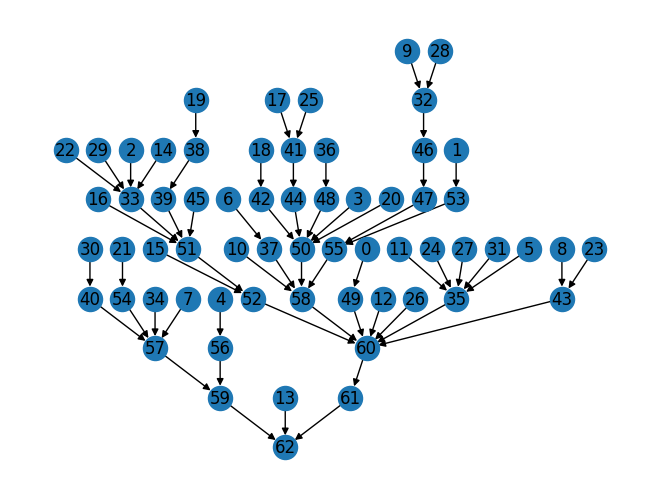

In [ ]:
adjacency_matrix = discretize_tree_topology(z,63)

adjacency_matrix = adjacency_matrix.at[-1,-1].set(0)
G = nx.from_numpy_array(adjacency_matrix, create_using=nx.DiGraph)

# Compute the tree layout
pos = graphviz_layout(G, prog="dot")


# Draw the graph using the tree layout
nx.draw(G, pos, with_labels=True)


# Save the tree plot as a PDF file
plt.savefig('tree_plot.pdf')

plt.show()




In [ ]:
n_leaves = 32

label_names = {}
    
for i in range(0,adjacency_matrix.shape[0]):
  label_names[i] = str(i)


<ipython-input-221-ca0fbb728234>:19: DeprecationWarning:

nx.nx_pydot.graphviz_layout depends on the pydot package, which hasknown issues and is not actively maintained. Consider usingnx.nx_agraph.graphviz_layout instead.

See https://github.com/networkx/networkx/issues/5723



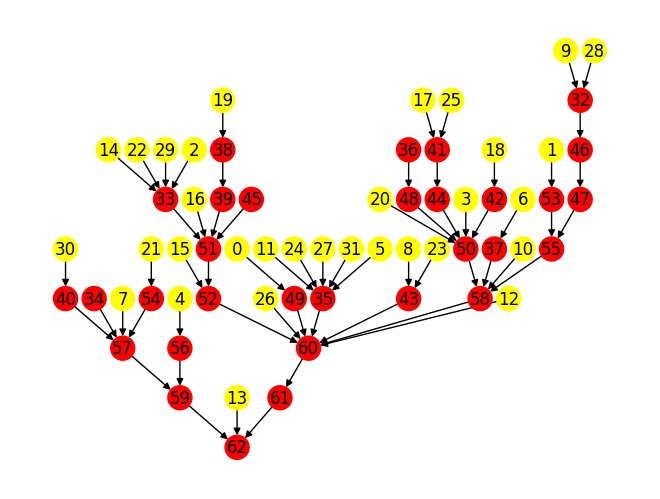

In [ ]:
rows, cols = np.where(adjacency_matrix == 1)
edges = zip(rows.tolist(), cols.tolist())


gr = nx.DiGraph()#nx.DiGraph
gr.add_edges_from(edges)

color_map = []
for node in gr:
    if(node >= n_leaves):
        color_map.append('red')
    else:
        color_map.append('yellow')
    

# color_map = ['red' if (node == 4 or node == 3) else 'yellow' for node in gr]        
fig = plt.figure()

pos = graphviz_layout(gr, prog="dot")
nx.draw(gr,pos,labels = label_names,with_labels=True, node_color = color_map)